<a href="https://colab.research.google.com/github/khvanri27/nn-practice-2026/blob/main/khvan640_01_cnn_classification_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание 2 (CNN)

Сделайте обучение сверточной нейронной сети на выбранном датасете:
- Создайте свой класс SimpleCNN с помощью PyTorch и обучите его
- Используйте предобученную сеть (например, ResNet).

Сравните полученные результаты и постройте визуализацию (графики, изображения и т д - см пример).

In [ ]:
%pip install kagglehub scikit-learn --quiet

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

100%|██████████| 157M/157M [00:01<00:00, 139MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


## 1. Импорты и данные

Датасет: Brain Tumor MRI (4 класса: glioma, meningioma, notumor, pituitary). Есть готовые папки `Training` и `Testing`. Из `Training` выделяем 15% на валидацию (по ней выбираем лучшую эпоху), `Testing` используем только для финальной оценки.

In [ ]:
import os, time, random, copy
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: cpu


In [ ]:
IMG_SIZE = 128
BATCH = 64
NUM_WORKERS = 0
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # статистики ImageNet

train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dir = os.path.join(path, "Training")
test_dir  = os.path.join(path, "Testing")

full_train = datasets.ImageFolder(train_dir, transform=train_tf)
full_val   = datasets.ImageFolder(train_dir, transform=eval_tf)
test_ds    = datasets.ImageFolder(test_dir,  transform=eval_tf)
classes     = full_train.classes
num_classes = len(classes)

perm  = np.random.permutation(len(full_train))
n_val = int(0.15 * len(perm))
val_ds   = Subset(full_val,   perm[:n_val].tolist())
train_ds = Subset(full_train, perm[n_val:].tolist())

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)

print("classes:", classes)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
train 4760 | val 840 | test 1600


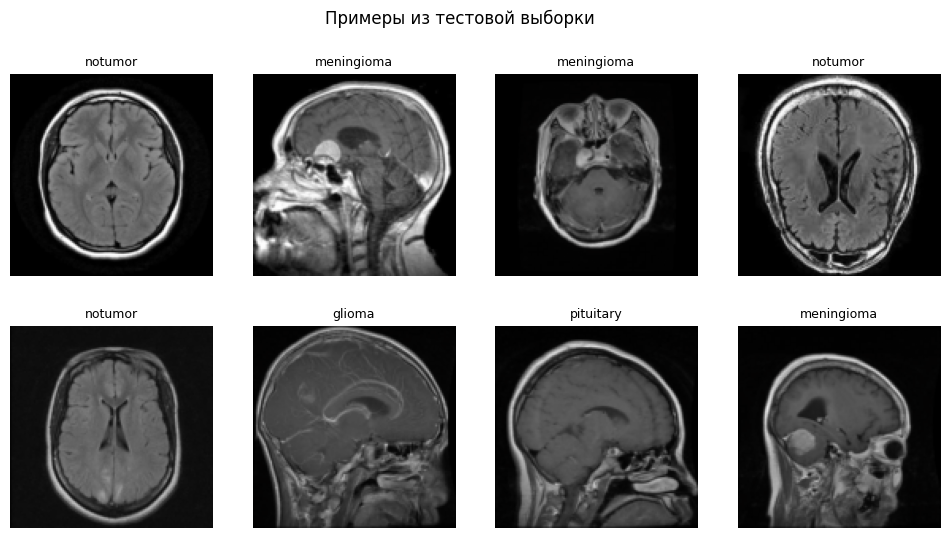

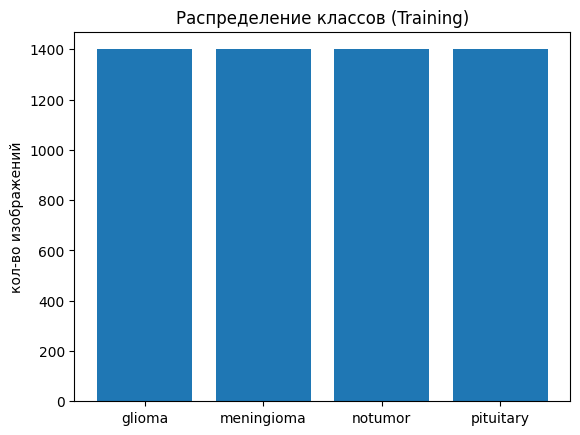

In [ ]:
# Примеры изображений
inv_mean, inv_std = torch.tensor(mean).view(3,1,1), torch.tensor(std).view(3,1,1)

def show_img(ax, x, title=""):
    ax.imshow((x.cpu() * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(title, fontsize=9); ax.axis("off")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, np.random.choice(len(test_ds), 8, replace=False)):
    x, y = test_ds[i]
    show_img(ax, x, classes[y])
plt.suptitle("Примеры из тестовой выборки"); plt.show()

counts = np.bincount(full_train.targets, minlength=num_classes)
plt.bar(classes, counts)
plt.title("Распределение классов (Training)")
plt.ylabel("кол-во изображений")
plt.show()

## 2. Своя CNN (SimpleCNN)

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256 * (IMG_SIZE // 16) ** 2, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(sum(p.numel() for p in SimpleCNN(num_classes).parameters()) / 1e6, "M параметров")

4.584964 M параметров


## 3. Функции обучения и оценки

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        correct  += (out.argmax(1) == y).sum().item()
        total    += y.size(0)
    return loss_sum / total, correct / total


def make_optimizer(model, lr, backbone_lr=None):
    """Если backbone_lr задан — отдельные LR для головы (fc) и backbone."""
    if backbone_lr is None:
        return torch.optim.Adam(model.parameters(), lr=lr)
    head_params, backbone_params = [], []
    for n, p in model.named_parameters():
        (head_params if n.startswith("fc.") else backbone_params).append(p)
    return torch.optim.Adam([
        {"params": head_params,     "lr": lr},
        {"params": backbone_params, "lr": backbone_lr},
    ])


def train(model, train_loader, val_loader, epochs, lr, backbone_lr=None, tag="model"):
    model.to(device)
    opt = make_optimizer(model, lr, backbone_lr)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    t0 = time.time()

    for ep in range(epochs):
        model.train()
        run_loss, run_correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out  = model(x)
            loss = F.cross_entropy(out, y)
            loss.backward()
            opt.step()
            run_loss    += loss.item() * y.size(0)
            run_correct += (out.argmax(1) == y).sum().item()
            n           += y.size(0)

        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(run_correct / n)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)

        if va > best_acc:
            best_acc  = va
            best_state = copy.deepcopy(model.state_dict())

        print(f"[{tag}] ep {ep+1:2d}/{epochs} | "
              f"train loss {run_loss/n:.3f} acc {run_correct/n:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f}")

    hist["time"] = time.time() - t0
    model.load_state_dict(best_state)
    print(f"[{tag}] best val acc = {best_acc:.4f} за {hist['time']:.1f}s")
    return hist


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(1).cpu())
        labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

## 4. Обучение своей CNN

In [ ]:
EPOCHS = 10
cnn = SimpleCNN(num_classes)
hist_cnn = train(cnn, train_loader, val_loader, epochs=EPOCHS, lr=1e-3, tag="SimpleCNN")

[SimpleCNN] ep  1/10 | train loss 1.322 acc 0.572 | val loss 0.715 acc 0.698
[SimpleCNN] ep  2/10 | train loss 0.694 acc 0.721 | val loss 0.528 acc 0.801
[SimpleCNN] ep  3/10 | train loss 0.590 acc 0.765 | val loss 0.520 acc 0.796
[SimpleCNN] ep  4/10 | train loss 0.540 acc 0.788 | val loss 0.412 acc 0.850
[SimpleCNN] ep  5/10 | train loss 0.484 acc 0.814 | val loss 0.493 acc 0.829
[SimpleCNN] ep  6/10 | train loss 0.455 acc 0.822 | val loss 0.346 acc 0.879
[SimpleCNN] ep  7/10 | train loss 0.406 acc 0.842 | val loss 0.292 acc 0.890
[SimpleCNN] ep  8/10 | train loss 0.377 acc 0.858 | val loss 0.324 acc 0.890
[SimpleCNN] ep  9/10 | train loss 0.356 acc 0.863 | val loss 0.339 acc 0.876
[SimpleCNN] ep 10/10 | train loss 0.357 acc 0.866 | val loss 0.295 acc 0.883
[SimpleCNN] best val acc = 0.8905 за 2524.3s


## 5. Предобученный ResNet18 (fine-tuning)

Берем ResNet18 с весами ImageNet, заменяем последний слой под 4 класса и дообучаем всю сеть с маленьким learning rate.

In [ ]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, num_classes)

hist_res = train(
    resnet, train_loader, val_loader,
    epochs=EPOCHS,
    lr=1e-3,
    backbone_lr=1e-5,
    tag="ResNet18",
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 143MB/s]


[ResNet18] ep  1/10 | train loss 0.625 acc 0.758 | val loss 0.359 acc 0.869
[ResNet18] ep  2/10 | train loss 0.306 acc 0.887 | val loss 0.282 acc 0.893
[ResNet18] ep  3/10 | train loss 0.231 acc 0.915 | val loss 0.196 acc 0.921
[ResNet18] ep  4/10 | train loss 0.178 acc 0.932 | val loss 0.177 acc 0.939
[ResNet18] ep  5/10 | train loss 0.143 acc 0.947 | val loss 0.143 acc 0.949
[ResNet18] ep  6/10 | train loss 0.118 acc 0.960 | val loss 0.121 acc 0.955
[ResNet18] ep  7/10 | train loss 0.096 acc 0.964 | val loss 0.100 acc 0.962
[ResNet18] ep  8/10 | train loss 0.079 acc 0.972 | val loss 0.097 acc 0.961
[ResNet18] ep  9/10 | train loss 0.063 acc 0.979 | val loss 0.094 acc 0.968
[ResNet18] ep 10/10 | train loss 0.048 acc 0.984 | val loss 0.086 acc 0.974
[ResNet18] best val acc = 0.9738 за 3442.5s


## 6. Сравнение: графики

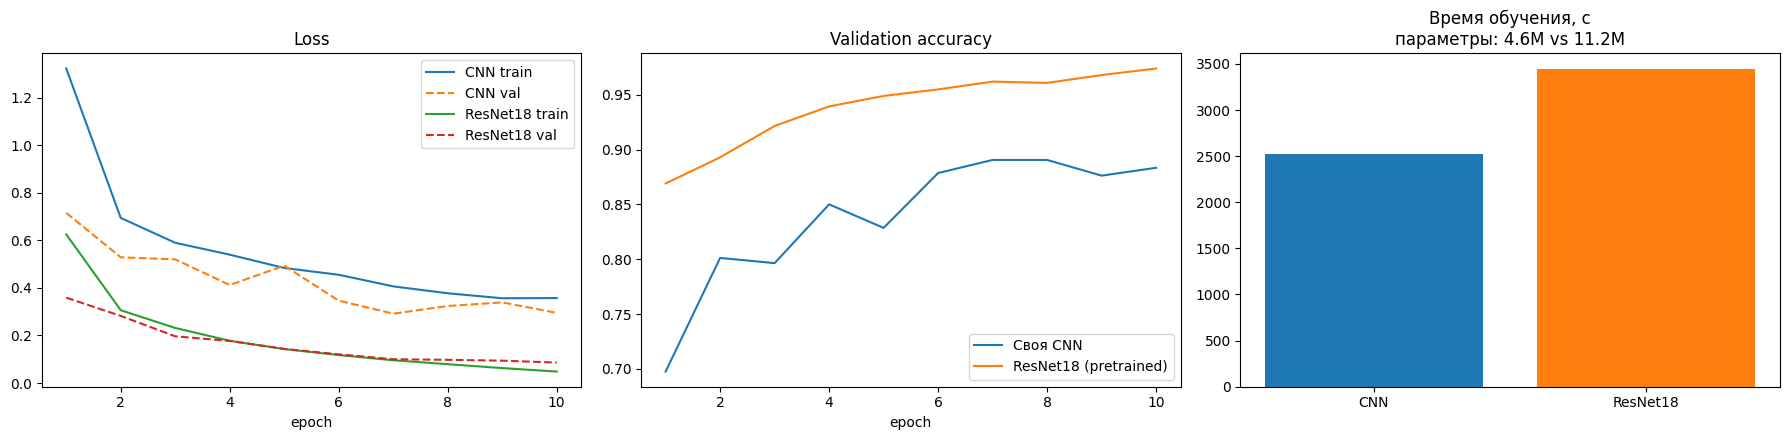

In [ ]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

ax[0].plot(ep, hist_cnn["train_loss"], label="CNN train")
ax[0].plot(ep, hist_cnn["val_loss"], "--", label="CNN val")
ax[0].plot(ep, hist_res["train_loss"], label="ResNet18 train")
ax[0].plot(ep, hist_res["val_loss"], "--", label="ResNet18 val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(ep, hist_cnn["val_acc"], label="Своя CNN")
ax[1].plot(ep, hist_res["val_acc"], label="ResNet18 (pretrained)")
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()

n_cnn = sum(p.numel() for p in cnn.parameters())
n_res = sum(p.numel() for p in resnet.parameters())
ax[2].bar(["CNN", "ResNet18"], [hist_cnn["time"], hist_res["time"]], color=["tab:blue", "tab:orange"])
ax[2].set_title(f"Время обучения, с\nпараметры: {n_cnn/1e6:.1f}M vs {n_res/1e6:.1f}M")
plt.tight_layout(); plt.show()

## 7. Финальная оценка на тестовой выборке

===== Своя CNN: test accuracy = 0.8087 =====
              precision    recall  f1-score   support

      glioma      0.892     0.662     0.760       400
  meningioma      0.726     0.667     0.695       400
     notumor      0.742     0.985     0.846       400
   pituitary      0.911     0.920     0.915       400

    accuracy                          0.809      1600
   macro avg      0.818     0.809     0.804      1600
weighted avg      0.818     0.809     0.804      1600

===== ResNet18: test accuracy = 0.9231 =====
              precision    recall  f1-score   support

      glioma      0.984     0.755     0.854       400
  meningioma      0.823     0.950     0.882       400
     notumor      0.955     0.998     0.976       400
   pituitary      0.959     0.990     0.974       400

    accuracy                          0.923      1600
   macro avg      0.930     0.923     0.921      1600
weighted avg      0.930     0.923     0.921      1600



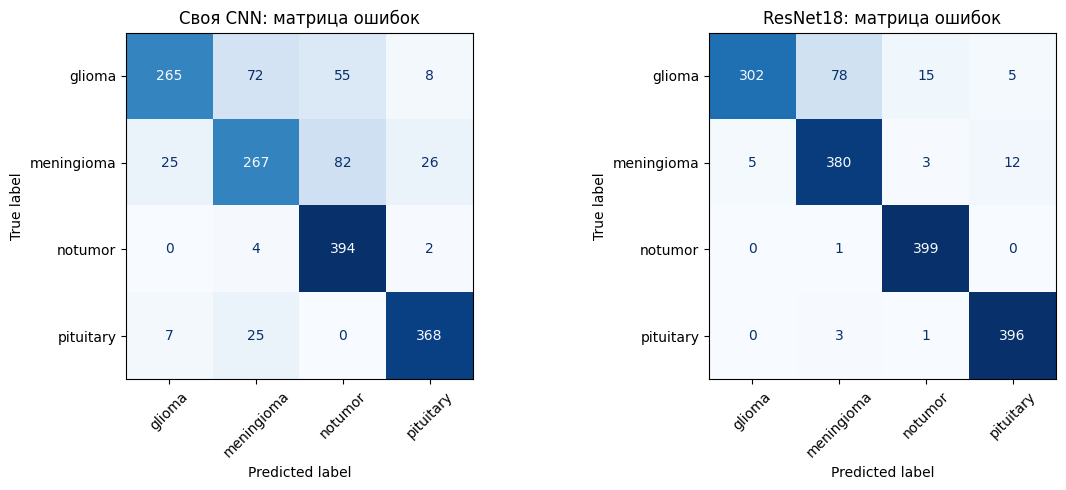

In [ ]:
results = {}
for name, model in [("Своя CNN", cnn), ("ResNet18", resnet)]:
    preds, labels = predict(model, test_loader)
    results[name] = (preds, labels)
    print(f"===== {name}: test accuracy = {(preds == labels).mean():.4f} =====")
    print(classification_report(labels, preds, target_names=classes, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (preds, labels)) in zip(axes, results.items()):
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}: матрица ошибок")
plt.tight_layout(); plt.show()

Своя CNN: ошибок 306 из 1600


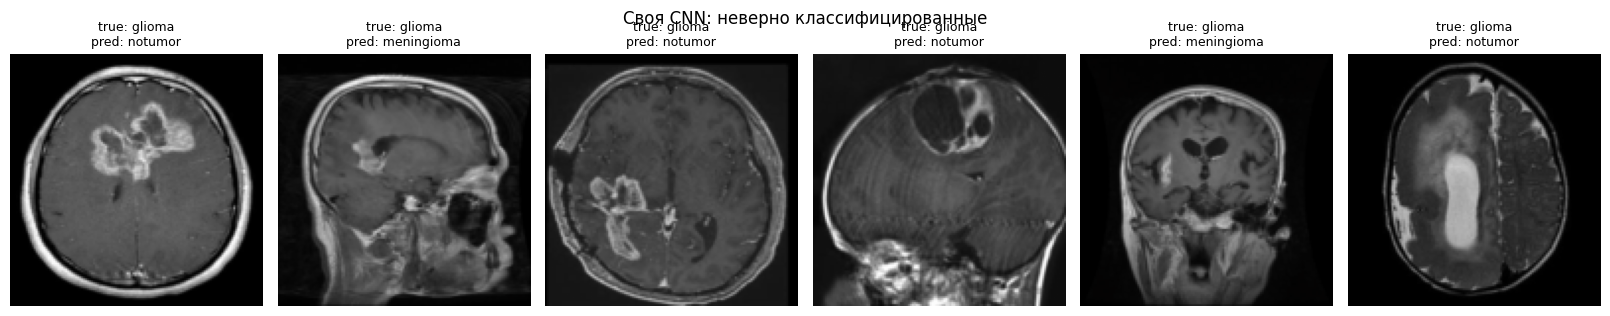

ResNet18: ошибок 123 из 1600


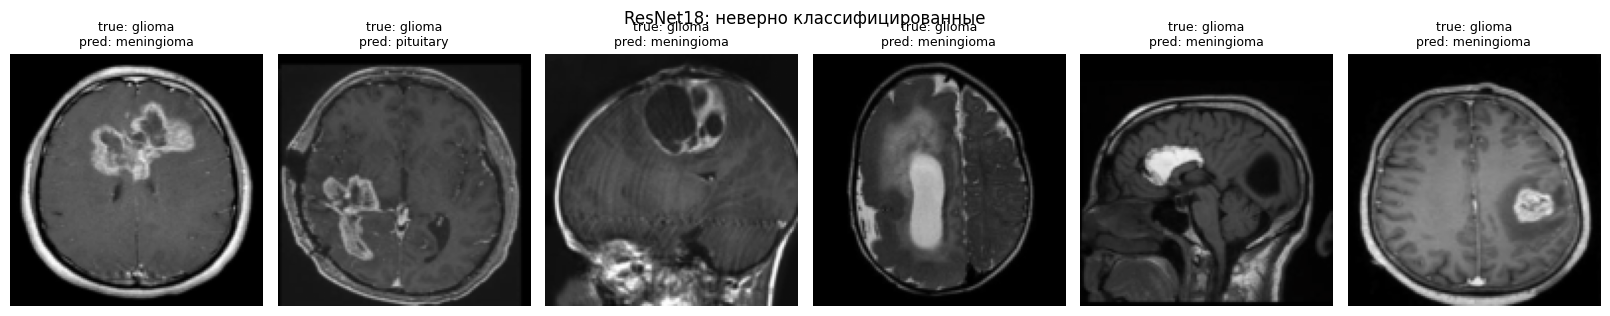

In [ ]:
# Примеры ошибок каждой модели
for name, (preds, labels) in results.items():
    wrong = np.where(preds != labels)[0]
    print(f"{name}: ошибок {len(wrong)} из {len(labels)}")
    if len(wrong) == 0:
        print("  - идеальная классификация, показать нечего")
        continue
    k = min(6, len(wrong))
    fig, axes = plt.subplots(1, k, figsize=(2.7 * k, 3.2))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, wrong[:k]):
        x, _ = test_ds[i]
        show_img(ax, x, f"true: {classes[labels[i]]}\npred: {classes[preds[i]]}")
    plt.suptitle(f"{name}: неверно классифицированные")
    plt.tight_layout(); plt.show()

## 8. Выводы

**Результаты на тесте:**

| Модель | Test accuracy | Параметры | Время обучения |
|---|---|---|---|
| SimpleCNN | 0.8087 | 4.6 M | ~2500 s |
| ResNet18 | 0.9231 | 11.2 M | ~3400 s |

**Как обучались:**
SimpleCNN вышла на плато к 6 эпохе, точность остановилась на ~0.88. ResNet18 сразу показала ~0.87 после первой эпохи и плавно дошла до ~0.97. Видно, что ResNet учится стабильнее.

**Ошибки:**
Обе модели чаще всего путают glioma и meningioma — они похожи на снимках. У SimpleCNN хуже всего с glioma (recall 0.66), а notumor распознается почти идеально. У ResNet ошибок в разы меньше.

**Причины почему ResNet лучше:**
Она уже обучена на ImageNet, поэтому знает базовые признаки (контуры, текстуры). Разные learning rate (1e-3 для головы, 1e-5 для базы) помогли не испортить эти веса.

**Про аугментации:**
RandomHorizontalFlip для МРТ подойдет для классификации опухолей нормально. RandomRotation(10) будет более безопасной.

**Итог:**
ResNet выигрывает по точности (0.92 против 0.81), но учится дольше. Своя CNN может быть достаточной, если данных много и они сильно отличаются от обычных картинок.